<a href="https://colab.research.google.com/github/medooMallahi/pump-doc-ai/blob/main/pump_doc_ai.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pump Doc AI — Automated Extraction of Technical Parameters from Equipment Documents

**Author:** Mohammed Almallahi · **Status:** Proof of Concept · **Stack:** Python, PyMuPDF, Ollama (Qwen2.5-7B, local), Pydantic

---

### The problem
Water infrastructure operators manage thousands of technical documents (datasheets, manuals)
from many manufacturers. Each one uses its own layout, language and units.
Today, technical parameters are typed into the asset database **by hand**.

### The goal
Automatically extract parameters such as power, flow, speed and current from these documents,
normalize them to standard units, and make them ready to load into a database.

### Approach
1. **Dataset:** 12 datasheets from 3 manufacturers with different layouts (table, bilingual grid, free text), 4 manuals, 4 scanned pages, plus a hand-checked answer key
2. **Baseline:** rule-based extraction (regular expressions)
3. **AI extraction:** a local open-source LLM with a strict output schema (data never leaves the machine)
4. **Evaluation:** every value compared against the answer key

### Results so far
| Method | Accuracy |
|---|---|
| Rule-based baseline (5 fields) | **80.0 %** |
| Local LLM (same 5 fields) | **100 %** |
| Local LLM (all 19 fields, 12 documents) | **100 %** |


In [1]:
!pip install -q pymupdf pandas

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path


PROJECT = Path('/content/drive/MyDrive/pump-doc-ai')

folders = [
    'data/raw/datasheets',
    'data/raw/manuals',
    'data/raw/scans',
    'data/processed',
    'data/ground_truth',
    'notebooks',
    'src',
]

for f in folders:
    (PROJECT / f).mkdir(parents=True, exist_ok=True)

print("Project structure created:")
for p in sorted(PROJECT.rglob('*')):
    if p.is_dir():
        print("  ", p.relative_to(PROJECT))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 99.5 MB/s eta 0:00:00
Mounted at /content/drive
Project structure created:
   data
   data/ground_truth
   data/processed
   data/raw
   data/raw/datasheets
   data/raw/manuals
   data/raw/scans
   notebooks
   src


In [2]:
import pandas as pd


gt = pd.read_csv(PROJECT / 'data/ground_truth/datasheets_ground_truth.csv')
qa = pd.read_csv(PROJECT / 'data/ground_truth/manuals_qa_ground_truth.csv')
print("Datasheet ground truth:", gt.shape)
print("Manual Q&A ground truth:", qa.shape)

ds_folder = PROJECT / 'data/raw/datasheets'
missing = [f for f in gt['file'] if not (ds_folder / f).exists()]
print("Missing datasheet PDFs:", missing if missing else "none ✓")


for folder in ['datasheets', 'manuals', 'scans']:
    n = len(list((PROJECT / 'data/raw' / folder).glob('*')))
    print(f"{folder}: {n} files")

gt.head()

Datasheet ground truth: (12, 23)
Manual Q&A ground truth: (36, 5)
Missing datasheet PDFs: none ✓
datasheets: 12 files
manuals: 4 files
scans: 8 files


,doc_id,file,manufacturer,model,pump_type,rated_power_kW,rated_flow_m3h,max_head_m,speed_rpm,voltage_V,...,max_solids_mm,outlet_DN,weight_kg,ip_rating,insulation_class,max_liquid_temp_C,max_submergence_m,cable_length_m,seal_type,efficiency_class
0,DS01,DS01_HV-S075-2C.pdf,Hydrovane Pumps NV,HV-S075-2C,Dry-installed sewage pump,7.5,80.4,20.6,2890,400,...,100,65,125,IP68,F,40,10,10,Double mechanical seal SiC/SiC,IE4
1,DS02,DS02_HV-X370-2B.pdf,Hydrovane Pumps NV,HV-X370-2B,Stormwater propeller pump,37.0,501.3,17.8,2920,400,...,100,100,518,IP68,F,40,30,15,Double mechanical seal SiC/WC,IE3
2,DS03,DS03_HV-K040-4C.pdf,Hydrovane Pumps NV,HV-K040-4C,Dry-installed sewage pump,4.0,38.6,22.7,1450,400,...,76,65,86,IP68,F,50,10,20,Double mechanical seal SiC/WC,IE4
3,DS04,DS04_HV-K220-4A.pdf,Hydrovane Pumps NV,HV-K220-4A,Stormwater propeller pump,22.0,208.7,26.0,1440,400,...,65,65,275,IP68,H,60,20,10,Double mechanical seal SiC/WC,IE3
4,DS05,DS05_AT-X022-4C.pdf,AquaTorq GmbH,AT-X022-4C,Dry-installed sewage pump,2.2,34.2,15.8,1450,400,...,65,80,60,IP68,H,60,30,20,Double mechanical seal SiC/SiC,IE4


In [3]:
import fitz

rows = []
for folder in ['datasheets', 'manuals', 'scans']:
    for pdf_path in sorted((PROJECT / 'data/raw' / folder).glob('*.pdf')):
        doc = fitz.open(pdf_path)
        text = "".join(page.get_text() for page in doc)
        rows.append({
            'file': pdf_path.name,
            'folder': folder,
            'pages': len(doc),
            'characters': len(text),
            'needs_ocr': len(text.strip()) < 50,
        })
        doc.close()

inventory = pd.DataFrame(rows)
inventory.to_csv(PROJECT / 'data/processed/documents_inventory.csv', index=False)
inventory

,file,folder,pages,characters,needs_ocr
0,DS01_HV-S075-2C.pdf,datasheets,1,832,False
1,DS02_HV-X370-2B.pdf,datasheets,1,828,False
2,DS03_HV-K040-4C.pdf,datasheets,1,836,False
3,DS04_HV-K220-4A.pdf,datasheets,1,822,False
4,DS05_AT-X022-4C.pdf,datasheets,1,1073,False
5,DS06_AT-S110-4A.pdf,datasheets,1,1097,False
6,DS07_AT-M450-4C.pdf,datasheets,1,1091,False
7,DS08_AT-M055-4C.pdf,datasheets,1,1100,False
8,DS09_NF-K300-4C.pdf,datasheets,1,1127,False
9,DS10_NF-M030-4A.pdf,datasheets,1,1113,False


## Part 2 — What can the computer read?
Compare the raw text PyMuPDF extracts from the three datasheet layouts.

In [4]:
import pymupdf

RAW = PROJECT / 'data/raw'

examples = {
    'Table layout (Hydrovane)':    'DS01_HV-S075-2C.pdf',
    'Key-value layout (AquaTorq)': 'DS05_AT-X022-4C.pdf',
    'Prose layout (NordFlux)':     'DS09_NF-K300-4C.pdf',
}

for name, file in examples.items():
    doc = pymupdf.open(RAW / 'datasheets' / file)
    text = doc[0].get_text()
    print("=" * 70)
    print(name, "→", file)
    print("=" * 70)
    print(text[:900])
    print()

Table layout (Hydrovane) → DS01_HV-S075-2C.pdf
HYDROVANE PUMPS NV
HV-S075-2C
Dry-installed sewage pump — Technical datasheet
The HV-S075-2C is designed for pumping raw sewage, wastewater with long fibres and sludge in municipal
and industrial pumping stations. Robust cast-iron construction (EN-GJL-250) and a single-channel impeller
ensure clog-free operation.
Technical data
Parameter
Value
Rated power P2
7.5 kW
Rated flow Q
80.4 m³/h
Max. head H
20.6 m
Speed
2890 rpm
Voltage / frequency
3~ 400 V / 50 Hz
Rated current
14.5 A
Impeller
Single-channel
Free passage
100 mm
Discharge
DN 65
Weight (without cable)
125 kg
Protection / insulation
IP68 / class F
Max. liquid temperature
40 °C
Max. immersion depth
10 m
Cable length
10 m
Shaft seal
Double mechanical seal SiC/SiC
Motor efficiency class
IE4
Hydrovane Pumps NV · Belgium · Doc. DS01-rev.B · FICTIONAL PRACTICE DOCUMENT


Key-value layout (AquaTorq) → DS05_AT-X022-4C.pdf
AQUATORQ GMBH
AT-X022-4C
Dry-installed sewage pump — Technical datash

In [5]:
import re


PATTERNS = {
    'rated_power_kW':  r'(\d+(?:\.\d+)?)\s*kW',
    'rated_flow_m3h':  r'(\d+(?:\.\d+)?)\s*m³/h',
    'speed_rpm':       r'(\d{3,4})\s*rpm',
    'rated_current_A': r'(\d+(?:\.\d+)?)\s*A\b',
    'weight_kg':       r'(\d+(?:\.\d+)?)\s*kg',
}

def extract_with_regex(text):
    result = {}
    for field, pattern in PATTERNS.items():
        match = re.search(pattern, text)
        result[field] = float(match.group(1)) if match else None
    return result


rows = []
for _, truth in gt.iterrows():
    text = pymupdf.open(RAW / 'datasheets' / truth['file'])[0].get_text()
    pred = extract_with_regex(text)
    for field in PATTERNS:
        correct = pred[field] is not None and abs(pred[field] - truth[field]) < 0.01
        rows.append({'doc_id': truth['doc_id'], 'manufacturer': truth['manufacturer'],
                     'field': field, 'predicted': pred[field],
                     'expected': truth[field], 'correct': correct})

results = pd.DataFrame(rows)


print("Overall accuracy:", round(results['correct'].mean() * 100, 1), "%\n")
results.pivot_table(index='field', columns='manufacturer', values='correct', aggfunc='mean').round(2)

Overall accuracy: 80.0 %



manufacturer,AquaTorq GmbH,Hydrovane Pumps NV,NordFlux BV
field,,,
rated_current_A,0.75,0.75,0.5
rated_flow_m3h,0.00,1.00,1.0
rated_power_kW,1.00,1.00,1.0
speed_rpm,0.00,1.00,1.0
weight_kg,1.00,1.00,1.0


## Part 3 — LLM extraction (local open-source model)
Run Qwen2.5-7B locally with Ollama, extract parameters into a fixed schema,
and compare with the regex baseline (80%).

In [6]:

!sudo apt-get install -y -qq zstd > /dev/null
!curl -fsSL https://ollama.com/install.sh | sh
!pip install -q ollama pydantic


import subprocess, time
subprocess.Popen(['ollama', 'serve'], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
time.sleep(5)


!ollama pull qwen2.5:7b

debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.



In [7]:
from pydantic import BaseModel, Field
from typing import Optional

class PumpSpec(BaseModel):
    model: Optional[str] = Field(..., description="Pump model code, e.g. HV-S075-2C")
    rated_power_kW: Optional[float] = Field(..., description="Rated motor power in kW (convert hp → kW)")
    rated_flow_m3h: Optional[float] = Field(..., description="Rated/duty flow in m³/h (convert l/s → m³/h)")
    max_head_m: Optional[float] = Field(..., description="Maximum head in metres (shut-off head)")
    speed_rpm: Optional[int] = Field(..., description="Rotational speed in rpm (min⁻¹ = rpm)")
    voltage_V: Optional[int] = Field(..., description="Supply voltage in volts")
    frequency_Hz: Optional[int] = Field(..., description="Supply frequency in Hz")
    rated_current_A: Optional[float] = Field(..., description="Rated/nominal current in amperes")
    impeller_type: Optional[str] = Field(..., description="Impeller type, e.g. Vortex, Single-channel")
    max_solids_mm: Optional[int] = Field(..., description="Free passage / max solids size in mm")
    outlet_DN: Optional[int] = Field(..., description="Discharge/outlet nominal diameter, number only (DN 80 → 80)")
    weight_kg: Optional[float] = Field(..., description="Pump weight in kg")
    ip_rating: Optional[str] = Field(..., description="Protection class, e.g. IP68")
    insulation_class: Optional[str] = Field(..., description="Motor insulation class letter, e.g. F")
    max_liquid_temp_C: Optional[int] = Field(..., description="Maximum liquid temperature in °C")
    max_submergence_m: Optional[int] = Field(..., description="Maximum immersion/submergence depth in m")
    cable_length_m: Optional[int] = Field(..., description="Cable length in m")
    seal_type: Optional[str] = Field(..., description="Seal type and material pair only, e.g. 'Double mechanical seal SiC/SiC'. No extra words about location, oil or operation.")
    efficiency_class: Optional[str] = Field(..., description="Motor efficiency class, e.g. IE3")

In [8]:
import ollama

MODEL = "qwen2.5:7b"


FIELD_LIST = "\n".join(
    f"- {name}: {field.description}" for name, field in PumpSpec.model_fields.items()
)

SYSTEM_PROMPT = f"""You extract technical parameters from pump datasheets.

Fill in ALL of these fields:
{FIELD_LIST}

Rules:
- Only use information that is explicitly in the document. If a value is missing, use null. Never guess.
- Labels may be in English, German or Dutch, and may be split over two lines.
- Convert all values to the units in the field list (e.g. hp → kW, l/s → m³/h; 1 l/s = 3.6 m³/h).
- Return numbers without units.
- For text fields, return only the value itself, not the rest of the sentence."""

def extract_with_llm(text: str, debug: bool = False) -> PumpSpec:
    response = ollama.chat(
        model=MODEL,
        messages=[
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": f"Datasheet text:\n\n{text}"},
        ],
        format=PumpSpec.model_json_schema(),
        options={"temperature": 0},
    )
    if debug:
        print(response.message.content)
    return PumpSpec.model_validate_json(response.message.content)

In [9]:
text = pymupdf.open(RAW / 'datasheets' / 'DS05_AT-X022-4C.pdf')[0].get_text()
spec = extract_with_llm(text, debug=True)

truth = gt[gt['doc_id'] == 'DS05'].iloc[0]
pd.DataFrame({'LLM': spec.model_dump(),
              'Ground truth': {k: truth[k] for k in spec.model_dump()}})

{
  "model": "AT-X022-4C",
  "rated_power_kW": 2.2,
  "rated_flow_m3h": 34.2,
  "max_head_m": 15.8,
  "speed_rpm": 1450,
  "voltage_V": 400,
  "frequency_Hz": 50,
  "rated_current_A": 4.2,
  "impeller_type": "Vortex",
  "max_solids_mm": 65,
  "outlet_DN": 80,
  "weight_kg": 60,
  "ip_rating": "IP68",
  "insulation_class": "H",
  "max_liquid_temp_C": 60,
  "max_submergence_m": 30,
  "cable_length_m": 20,
  "seal_type": "Double mechanical seal SiC/SiC",
  "efficiency_class": "IE4"
}


,LLM,Ground truth
model,AT-X022-4C,AT-X022-4C
rated_power_kW,2.2,2.2
rated_flow_m3h,34.2,34.2
max_head_m,15.8,15.8
speed_rpm,1450,1450
voltage_V,400,400
frequency_Hz,50,50
rated_current_A,4.2,4.2
impeller_type,Vortex,Vortex
max_solids_mm,65,65


In [10]:
import time


predictions = []
for _, row in gt.iterrows():
    start = time.time()
    text = pymupdf.open(RAW / 'datasheets' / row['file'])[0].get_text()
    spec = extract_with_llm(text)
    predictions.append({'doc_id': row['doc_id'], **spec.model_dump()})
    print(f"{row['doc_id']} done in {time.time() - start:.1f}s")

pred_df = pd.DataFrame(predictions)

pred_df.to_csv(PROJECT / 'data/processed/llm_predictions_datasheets.csv', index=False)

DS01 done in 53.3s
DS02 done in 53.6s
DS03 done in 53.0s
DS04 done in 52.7s
DS05 done in 41.2s
DS06 done in 59.4s
DS07 done in 60.2s
DS08 done in 57.8s
DS09 done in 56.8s
DS10 done in 56.9s
DS11 done in 57.4s
DS12 done in 54.2s


In [11]:
import re
import pandas as pd
import pymupdf
import numbers


gt = pd.read_csv(PROJECT / 'data/ground_truth/datasheets_ground_truth.csv')
pred_df = pd.read_csv(PROJECT / 'data/processed/llm_predictions_datasheets.csv')
RAW = PROJECT / 'data/raw'


def is_correct(pred, truth):
    """Numbers: within 1% tolerance. Text: same after ignoring case and spaces."""
    if pred is None or pd.isna(pred):
        return False
    if isinstance(truth, numbers.Number) and not isinstance(truth, bool):   # also catches numpy numbers
        try:
            return abs(float(pred) - float(truth)) <= 0.01 * abs(float(truth)) + 1e-9
        except (ValueError, TypeError):
            return False
    norm = lambda s: str(s).strip().lower().replace(" ", "")
    return norm(pred) == norm(truth)


PATTERNS = {
    'rated_power_kW':  r'(\d+(?:\.\d+)?)\s*kW',
    'rated_flow_m3h':  r'(\d+(?:\.\d+)?)\s*m³/h',
    'speed_rpm':       r'(\d{3,4})\s*rpm',
    'rated_current_A': r'(\d+(?:\.\d+)?)\s*A\b',
    'weight_kg':       r'(\d+(?:\.\d+)?)\s*kg',
}
regex_rows = []
for _, truth in gt.iterrows():
    text = pymupdf.open(RAW / 'datasheets' / truth['file'])[0].get_text()
    for field, pattern in PATTERNS.items():
        m = re.search(pattern, text)
        pred = float(m.group(1)) if m else None
        regex_rows.append({'doc_id': truth['doc_id'], 'manufacturer': truth['manufacturer'],
                           'field': field, 'correct': is_correct(pred, truth[field])})
regex_results = pd.DataFrame(regex_rows)


fields = [c for c in pred_df.columns if c != 'doc_id']
llm_rows = []
for _, pred in pred_df.iterrows():
    truth = gt[gt['doc_id'] == pred['doc_id']].iloc[0]
    for f in fields:
        llm_rows.append({'doc_id': pred['doc_id'], 'manufacturer': truth['manufacturer'],
                         'field': f, 'predicted': pred[f], 'expected': truth[f],
                         'correct': is_correct(pred[f], truth[f])})
llm_results = pd.DataFrame(llm_rows)
llm_results.to_csv(PROJECT / 'data/processed/llm_evaluation_datasheets.csv', index=False)


same5 = llm_results[llm_results['field'].isin(PATTERNS.keys())]['correct'].mean()
print(f"Regex baseline (5 fields):  {regex_results['correct'].mean()*100:.1f} %")
print(f"LLM (same 5 fields):        {same5*100:.1f} %")
print(f"LLM (all {len(fields)} fields):        {llm_results['correct'].mean()*100:.1f} %")
print(f"Wrong values: {(~llm_results['correct']).sum()} of {len(llm_results)}\n")

llm_results.pivot_table(index='field', columns='manufacturer',
                        values='correct', aggfunc='mean').round(2)

Regex baseline (5 fields):  80.0 %
LLM (same 5 fields):        100.0 %
LLM (all 19 fields):        100.0 %
Wrong values: 0 of 228



manufacturer,AquaTorq GmbH,Hydrovane Pumps NV,NordFlux BV
field,,,
cable_length_m,1.0,1.0,1.0
efficiency_class,1.0,1.0,1.0
frequency_Hz,1.0,1.0,1.0
impeller_type,1.0,1.0,1.0
insulation_class,1.0,1.0,1.0
ip_rating,1.0,1.0,1.0
max_head_m,1.0,1.0,1.0
max_liquid_temp_C,1.0,1.0,1.0
max_solids_mm,1.0,1.0,1.0


## Showcase — one document, three answers
The datasheet on the left is the input. The table compares the **rule-based** extraction
and the **AI** extraction with the correct values.
✅ = correct · ❌ = wrong · — = not attempted by the rules

Parameter,Correct value,Rule-based,AI (local LLM)
Model,AT-X022-4C,—,✅ AT-X022-4C
Rated power (kW),2.2,✅ 2.2,✅ 2.2
Rated flow (m³/h),34.2,❌ —,✅ 34.2
Max. head (m),15.8,—,✅ 15.8
Speed (rpm),1450,❌ —,✅ 1450
Voltage (V),400,—,✅ 400
Frequency (Hz),50,—,✅ 50
Rated current (A),4.2,✅ 4.2,✅ 4.2
Impeller,Vortex,—,✅ Vortex
Free passage (mm),65,—,✅ 65

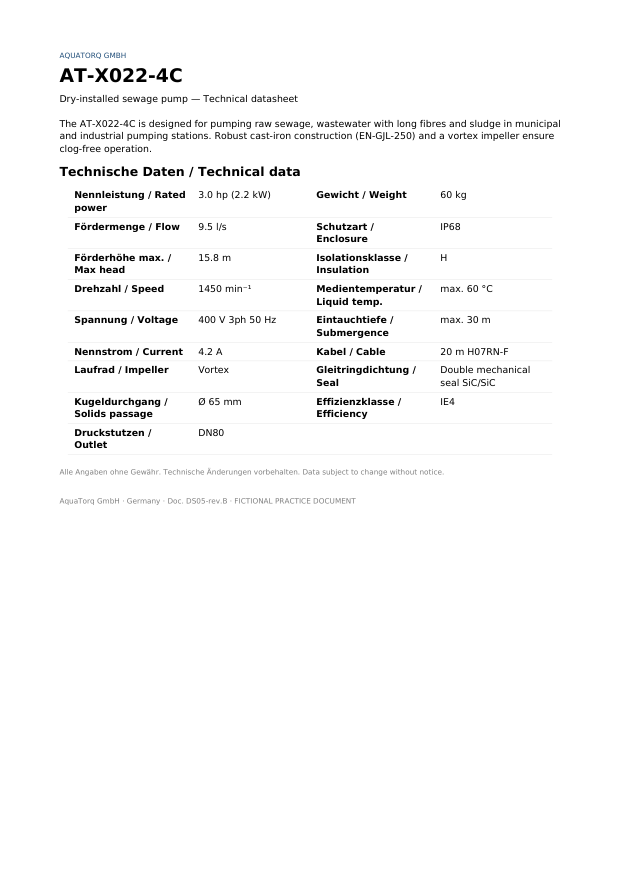

In [12]:
import base64, re
from IPython.display import HTML, display


PATTERNS = {
    'rated_power_kW':  r'(\d+(?:\.\d+)?)\s*kW',
    'rated_flow_m3h':  r'(\d+(?:\.\d+)?)\s*m³/h',
    'speed_rpm':       r'(\d{3,4})\s*rpm',
    'rated_current_A': r'(\d+(?:\.\d+)?)\s*A\b',
    'weight_kg':       r'(\d+(?:\.\d+)?)\s*kg',
}
def extract_with_regex(text):
    out = {}
    for field, pattern in PATTERNS.items():
        m = re.search(pattern, text)
        out[field] = float(m.group(1)) if m else None
    return out

LABELS = {
    'model': 'Model', 'rated_power_kW': 'Rated power (kW)', 'rated_flow_m3h': 'Rated flow (m³/h)',
    'max_head_m': 'Max. head (m)', 'speed_rpm': 'Speed (rpm)', 'voltage_V': 'Voltage (V)',
    'frequency_Hz': 'Frequency (Hz)', 'rated_current_A': 'Rated current (A)',
    'impeller_type': 'Impeller', 'max_solids_mm': 'Free passage (mm)', 'outlet_DN': 'Outlet (DN)',
    'weight_kg': 'Weight (kg)', 'ip_rating': 'Protection', 'insulation_class': 'Insulation class',
    'max_liquid_temp_C': 'Max. liquid temp. (°C)', 'max_submergence_m': 'Max. submergence (m)',
    'cable_length_m': 'Cable length (m)', 'seal_type': 'Shaft seal', 'efficiency_class': 'Efficiency class',
}

def fmt(v):
    if v is None or (isinstance(v, float) and pd.isna(v)):
        return "—"
    if isinstance(v, float) and v.is_integer():
        return str(int(v))
    return str(v)

def cell(value, ok):
    if ok is None:
        return '<td style="color:#999;text-align:center">—</td>'
    bg, icon = ('#e6f4ea', '✅') if ok else ('#fce8e6', '❌')
    return f'<td style="background:{bg}">{icon} {fmt(value)}</td>'

def show_document(doc_id):
    truth = gt[gt['doc_id'] == doc_id].iloc[0]
    pdf = RAW / 'datasheets' / truth['file']
    text = pymupdf.open(pdf)[0].get_text()
    rx = extract_with_regex(text)
    llm = pred_df[pred_df['doc_id'] == doc_id].iloc[0]


    png = pymupdf.open(pdf)[0].get_pixmap(dpi=75).tobytes("png")
    img = base64.b64encode(png).decode()


    rows, rx_ok, llm_ok = "", [], []
    for f, label in LABELS.items():
        r_ok = is_correct(rx[f], truth[f]) if f in rx else None
        l_ok = is_correct(llm[f], truth[f])
        if r_ok is not None: rx_ok.append(r_ok)
        llm_ok.append(l_ok)
        rows += (f'<tr><td><b>{label}</b></td><td>{fmt(truth[f])}</td>'
                 f'{cell(rx.get(f), r_ok)}{cell(llm[f], l_ok)}</tr>')

    html = f"""
    <div style="font-family:Arial, sans-serif; color:#222">
      <h3 style="margin-bottom:4px">{truth['model']} — {truth['manufacturer']}</h3>
      <p style="margin-top:0;color:#555">
        Rule-based: <b>{sum(rx_ok)}/{len(rx_ok)}</b> correct &nbsp;·&nbsp;
        AI (local LLM): <b>{sum(llm_ok)}/{len(llm_ok)}</b> correct
      </p>
      <div style="display:flex; gap:24px; align-items:flex-start">
        <img src="data:image/png;base64,{img}"
             style="width:420px; border:1px solid #ccc; box-shadow:0 2px 6px rgba(0,0,0,.15)">
        <table style="border-collapse:collapse; font-size:13px">
          <tr style="background:#1f4e79; color:white">
            <th style="padding:6px 10px;text-align:left">Parameter</th>
            <th style="padding:6px 10px;text-align:left">Correct value</th>
            <th style="padding:6px 10px;text-align:left">Rule-based</th>
            <th style="padding:6px 10px;text-align:left">AI (local LLM)</th>
          </tr>
          {rows}
        </table>
      </div>
    </div>
    <style> td {{ padding:5px 10px; border-bottom:1px solid #eee; }} </style>
    """
    display(HTML(html))

show_document('DS05')

### Finding: rules break on real-world variation (80 %)
- ✅ Works when the layout uses standard units (kW, m³/h, rpm)
- ❌ Fails on other units: **l/s** and **min⁻¹** (AquaTorq) → 0 % for flow and speed
- ❌ False positives: in model names like *HV-K220-**4A***, "4A" is read as a current of 4 A
- Every new manufacturer would need new rules → **does not scale**

### Finding: the local LLM reaches 100 % after three targeted fixes
| Iteration | Change | Result |
|---|---|---|
| 1 | Schema with optional fields | Model skipped most fields (5/19 on DS05) |
| 2 | All fields required + field list in prompt | 98.2 % |
| 3 | Clearer description for *seal type* + "value only" rule | **100 %** |

Also found and fixed a bug in the evaluation itself (numpy integers were compared as text).
Runs fully locally on a free T4 GPU, about **9 s per document**, so no data leaves the machine.

## Part 4 — Maintenance assistant for field technicians (RAG)
Technicians ask a question in plain language → the system finds the relevant manual sections →
a local LLM writes step-by-step instructions **with the source section** for every step.
Evaluated on 36 questions with known answers.

In [13]:
!ollama pull nomic-embed-text

import re, numpy as np, pandas as pd, pymupdf, ollama
from IPython.display import Markdown, display

EMBED_MODEL = "nomic-embed-text"
LLM_MODEL = "qwen2.5:7b"

In [14]:
SECTION_RE = re.compile(r'^(\d(?:\.\d)?)\.?\s+([A-Z][A-Za-z &/,-]{2,40})$')   # e.g. "4.2 Oil change"
MANUAL_RE  = re.compile(r'(MN\d+)_(.+)_manual\.pdf')                             # file name → id + pump model

def chunk_manual(pdf_path):
    manual_id, model = MANUAL_RE.match(pdf_path.name).groups()
    sections, current = [], None
    for page_no, page in enumerate(pymupdf.open(pdf_path), start=1):
        for line in page.get_text().splitlines():
            line = line.strip()
            if not line or 'FICTIONAL PRACTICE DOCUMENT' in line:
                continue
            m = SECTION_RE.match(line)
            if m:                                   # a new section starts here
                if current: sections.append(current)
                current = {'manual_id': manual_id, 'model': model, 'section': m.group(1),
                           'title': m.group(2), 'page': page_no, 'lines': []}
            elif current:
                current['lines'].append(line)
    if current: sections.append(current)

    chunks = []
    for s in sections:
        body = "\n".join(s.pop('lines'))
        if len(body) > 30:                          # skip empty headings like "4. Maintenance"
            chunks.append({**s, 'body': body})
    return chunks

all_chunks = []
for pdf in sorted((RAW / 'manuals').glob('*.pdf')):
    all_chunks += chunk_manual(pdf)
chunks = pd.DataFrame(all_chunks)

print(f"{len(chunks)} chunks from {chunks['manual_id'].nunique()} manuals\n")
chunks[['manual_id', 'model', 'section', 'title', 'page']].head(8)

32 chunks from 4 manuals



,manual_id,model,section,title,page
0,MN01,HV-S075-2C,1,Safety,1
1,MN01,HV-S075-2C,2,Installation,1
2,MN01,HV-S075-2C,3,Operation,1
3,MN01,HV-S075-2C,4.1,Maintenance schedule,2
4,MN01,HV-S075-2C,4.2,Oil change,2
5,MN01,HV-S075-2C,4.3,Replacing the mechanical seal,2
6,MN01,HV-S075-2C,4.4,Electrical check,2
7,MN01,HV-S075-2C,5,Troubleshooting,2


In [15]:
def chunk_text(row):
    return f"search_document: Manual {row.manual_id} for pump {row.model}. Section {row.section} {row.title}.\n{row.body}"

response = ollama.embed(model=EMBED_MODEL, input=[chunk_text(r) for r in chunks.itertuples()])
EMB = np.array(response['embeddings'])
EMB = EMB / np.linalg.norm(EMB, axis=1, keepdims=True)

print("Embedding matrix:", EMB.shape)

Embedding matrix: (32, 768)


In [16]:
def retrieve(question, model=None, k=3):
    q = np.array(ollama.embed(model=EMBED_MODEL, input=[f"search_query: {question}"])['embeddings'][0])
    q = q / np.linalg.norm(q)
    results = chunks.assign(score=EMB @ q)
    if model:
        results = results[results['model'] == model]
    return results.sort_values('score', ascending=False).head(k)

hits = retrieve("Seal leakage alarm. What should I do?", model="HV-S075-2C")
hits[['manual_id', 'section', 'title', 'score']]

,manual_id,section,title,score
0,MN01,1,Safety,0.639461
5,MN01,4.3,Replacing the mechanical seal,0.637028
3,MN01,4.1,Maintenance schedule,0.613724


In [21]:
REF_RE = re.compile(r'\b(\d\.\d)\b')

def retrieve_with_refs(question, model=None, k=3):
    hits = retrieve(question, model, k)
    refs = set()
    for body in hits['body']:
        refs |= set(REF_RE.findall(body))
    extra = chunks[chunks['section'].isin(refs) & ~chunks['section'].isin(hits['section'])]
    if model:
        extra = extra[extra['model'] == model]
    return pd.concat([hits, extra])

ANSWER_PROMPT = """You are a maintenance assistant for field technicians at a wastewater utility.
Answer ONLY with information from the manual sections provided.
- If the task involves working on the pump, ALWAYS start with a safety reminder from the Safety section.
- Give clear numbered steps. Include the actual steps and values (torques, quantities, oil type,
  clearances, intervals) from the referenced procedures. Do NOT just say "see section X".
- Give values exactly as written in the manual.
- After each step or fact, cite the source like [MN01 §4.2].
- If the sections do not contain the answer, reply: "Not found in the manual." Never guess."""

def ask(question, model=None, k=3):
    hits = retrieve_with_refs(question, model, k)
    context = "\n\n".join(
        f"[{r.manual_id} §{r.section} – {r.title}, page {r.page}]\n{r.body}" for r in hits.itertuples()
    )
    response = ollama.chat(
        model=LLM_MODEL,
        messages=[{"role": "system", "content": ANSWER_PROMPT},
                  {"role": "user", "content": f"Manual sections:\n\n{context}\n\nQuestion: {question}"}],
        options={"temperature": 0},
    )
    return response.message.content, hits

In [18]:
qa = pd.read_csv(PROJECT / 'data/ground_truth/manuals_qa_ground_truth.csv', dtype={'section': str})

def numbers_in(text):
    text = re.sub(r'(?<=\d)[,\s](?=\d{3}\b)', '', str(text))
    return {float(x) for x in re.findall(r'\d+(?:\.\d+)?', text)}

def judge(reference, answer):
    """For answers without numbers: let the LLM check if the key information is there."""
    prompt = (f"Reference answer: {reference}\nAssistant answer: {answer}\n\n"
              "Does the assistant answer contain the key information of the reference answer? "
              "Reply with only YES or NO.")
    r = ollama.chat(model=LLM_MODEL, messages=[{"role": "user", "content": prompt}], options={"temperature": 0})
    return r.message.content.strip().upper().startswith("YES")

rows = []
for i, q in enumerate(qa.itertuples(), 1):
    hits_filtered = retrieve(q.question, model=q.model)
    hits_all = retrieve(q.question)
    found_filtered = q.section in hits_filtered['section'].values
    found_all = ((hits_all['section'] == q.section) & (hits_all['manual_id'] == q.doc_id)).any()


    answer, _ = ask(q.question, model=q.model)
    expected_numbers = numbers_in(q.answer)
    if expected_numbers:
        answer_ok, method = expected_numbers <= numbers_in(answer), 'numbers'
    else:
        answer_ok, method = judge(q.answer, answer), 'LLM judge'

    rows.append({'doc_id': q.doc_id, 'question': q.question, 'expected': q.answer,
                 'answer': answer, 'section': q.section,
                 'retrieval_ok (with pump filter)': found_filtered,
                 'retrieval_ok (no filter)': found_all,
                 'answer_ok': answer_ok, 'check': method})
    print(f"{i}/{len(qa)} done")

rag_results = pd.DataFrame(rows)
rag_results.to_csv(PROJECT / 'data/processed/rag_evaluation.csv', index=False)

print(f"\nRetrieval, right section in top 3 (with pump filter): {rag_results['retrieval_ok (with pump filter)'].mean()*100:.1f} %")
print(f"Retrieval, right manual + section (no filter):        {rag_results['retrieval_ok (no filter)'].mean()*100:.1f} %")
print(f"Answer contains the correct information:              {rag_results['answer_ok'].mean()*100:.1f} %")

1/36 done
2/36 done
3/36 done
4/36 done
5/36 done
6/36 done
7/36 done
8/36 done
9/36 done
10/36 done
11/36 done
12/36 done
13/36 done
14/36 done
15/36 done
16/36 done
17/36 done
18/36 done
19/36 done
20/36 done
21/36 done
22/36 done
23/36 done
24/36 done
25/36 done
26/36 done
27/36 done
28/36 done
29/36 done
30/36 done
31/36 done
32/36 done
33/36 done
34/36 done
35/36 done
36/36 done

Retrieval, right section in top 3 (with pump filter): 100.0 %
Retrieval, right manual + section (no filter):        66.7 %
Answer contains the correct information:              88.9 %


## Demo — technician asks a question about a pump
1. Show the pump data extracted by the AI (Part 3)
2. Answer the question from the pump's own manual (RAG, Part 4), with source references

In [22]:
def demo(model, question):
    spec = pred_df[pred_df['model'] == model].iloc[0]
    print(f"🔧 Pump {model}")
    print(f"   Power: {spec['rated_power_kW']} kW | Current: {spec['rated_current_A']} A | "
          f"Speed: {spec['speed_rpm']} rpm | Seal: {spec['seal_type']}\n")

    answer, hits = ask(question, model=model)
    print(f"🧑‍🔧 Question: {question}\n")
    display(Markdown(answer))
    print("\n📄 Sections used:", ", ".join(f"{r.manual_id} §{r.section} {r.title}" for r in hits.itertuples()))

In [23]:
demo("HV-S075-2C", "Seal leakage alarm on my pump. What should I do?")

🔧 Pump HV-S075-2C
   Power: 7.5 kW | Current: 14.5 A | Speed: 2890 rpm | Seal: Double mechanical seal SiC/SiC

🧑‍🔧 Question: Seal leakage alarm on my pump. What should I do?



Based on the manual [MN01 §4.3], if you encounter a seal leakage alarm, you should follow these steps:

1. Isolate and lock out the power supply; lift the pump out and clean it. [MN01 §4.3, step 1]
2. Drain the oil from the seal chamber (see [MN01 §4.2]). [MN01 §4.3, step 2]
3. Replace the mechanical seal. [MN01 §4.3, step 6-7]
4. Refit the volute, refill oil, and perform an insulation test before reinstallation. [MN01 §4.3, step 8]

Specifically, the oil change procedure from [MN01 §4.2] states that the oil type is ISO VG 15 paraffin oil, the quantity is 0.8 litres, and the oil filling plug should be tightened to 45 Nm.


📄 Sections used: MN01 §1 Safety, MN01 §4.3 Replacing the mechanical seal, MN01 §5 Troubleshooting, MN01 §4.2 Oil change
